# 用双向 LSTM 做中文电影评论情感分类

**学习目标：**从训练数据构建词表，对评论做编码与补齐，训练对语序敏感的模型，
用验证集挑选检查点，并输出中文标签。

本课使用 ChnSentiCorp 中文酒店/影视评论，分词使用 jieba，而不是英文空格切分。
PyTorch 与 PaddlePaddle 两条路线共用同一份预处理数据和标签映射，但使用各自的环境与输出目录。


In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('paddlepaddle').split("+")[0] == '3.3.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('paddlepaddle' + "：", version('paddlepaddle'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
paddlepaddle： 3.3.1
运行模式： 课堂默认训练参数


**预期输出：**

```text
Python： 3.12.12
paddlepaddle： 3.3.1
运行模式： 课堂默认训练参数
```

In [2]:
from pathlib import Path
import os
import sys

# 不依赖当前工作目录，向上找到中文课程根目录。
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "CHINESE_COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("请在项目根目录（中文课程）中启动 Jupyter。")
ENGLISH = COURSE / "english"
# 中文专用模块在仓库根 common/，与英文课程共享的数据与检测模块在 english/common。
sys.path.insert(0, str(ENGLISH / "common"))
sys.path.insert(0, str(COURSE / "common"))
# 模型权重缓存与英文课程共用一份，避免同一份权重重复下载。
os.environ.setdefault("HF_HOME", str(ENGLISH / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(ENGLISH / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**预期输出：**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

（输出里的 `…` 代表运行本 notebook 时所在机器的仓库绝对路径前缀，你在自己机器上执行会看到自己的路径。）

In [3]:
FRAMEWORK = "paddle"
EXPERIMENT = "lstm-sentiment"

import json
import random
import numpy as np
from sentiment_cn import load_reviews, tokenize, build_vocab, encode, LABELS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
DATA = COURSE / "03-sentiment-analysis" / "data"
OUTPUT = COURSE / "03-sentiment-analysis" / "outputs" / FRAMEWORK / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
train_rows = load_reviews(DATA, "train", 64 if SMOKE else 4000)
validation_rows = load_reviews(DATA, "validation", 32 if SMOKE else 1000)
test_rows = load_reviews(DATA, "test", 32 if SMOKE else 1000)
print("数据集划分规模：", len(train_rows), len(validation_rows), len(test_rows))
print("标签：", LABELS)

数据集划分规模： 4000 1000 856
标签： ['负面', '正面']


**预期输出：**

```text
数据集划分规模： 4000 1000 856
标签： ['负面', '正面']
```

## 1. 构建不泄漏测试信息的词表

`<pad>` 固定为 ID 0，`<unk>` 固定为 ID 1。课堂实验会截断过长的评论，同时记录真实长度。
词表只在训练文本上拟合。“不”“没有”等否定词不要当停用词删掉。


In [4]:
MAX_LENGTH = 40 if SMOKE else 200
vocab = build_vocab([row["text"] for row in train_rows], max_words=20000)
(OUTPUT / "vocab.json").write_text(json.dumps(vocab, indent=2), encoding="utf-8")
ids, length = encode("演技没什么说服力，但我倒是喜欢配乐。", vocab, MAX_LENGTH)
print("词表规模：", len(vocab), "真实长度：", length)
print("前若干个 token ID：", ids[:12])
print("中文标签映射：", dict(enumerate(LABELS)))

/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


词表规模： 10530 真实长度： 9
前若干个 token ID： [1, 382, 1, 37, 5, 431, 4, 59, 1, 0, 0, 0]
中文标签映射： {0: '负面', 1: '正面'}


**预期输出：**

```text
/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
词表规模： 10530 真实长度： 9
前若干个 token ID： [1, 382, 1, 37, 5, 431, 4, 59, 1, 0, 0, 0]
中文标签映射： {0: '负面', 1: '正面'}
```

## 2. 定义模型与训练步骤

嵌入层把 ID 映射成向量；双向 LSTM 从两个方向总结整条评论；
把两个方向的最终状态拼接后送入二分类线性层。
计算循环网络时要传入真实长度，这样补齐用的 padding 不会污染最终状态。
梯度裁剪用于限制异常大的更新。


In [5]:
import paddle
from paddle import nn

paddle.seed(SEED)
paddle.set_device("gpu" if paddle.is_compiled_with_cuda() else "cpu")

class ReviewDataset(paddle.io.Dataset):
    def __init__(self, rows):
        super().__init__()
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        ids, length = encode(row["text"], vocab, MAX_LENGTH)
        return np.asarray(ids, dtype="int64"), np.int64(length), np.int64(row["label"])

def make_loader(rows, shuffle=False):
    return paddle.io.DataLoader(ReviewDataset(rows), batch_size=32, shuffle=shuffle,
                                num_workers=0, return_list=True)

class SentimentLSTM(nn.Layer):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, direction="bidirectional")
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, 2)

    def forward(self, ids, lengths):
        embedded = self.embedding(ids)
        # sequence_length prevents padding from becoming part of the final state.
        _, (hidden, _) = self.lstm(embedded, sequence_length=lengths)
        return self.classifier(self.dropout(paddle.concat([hidden[-2], hidden[-1]], axis=1)))

model = SentimentLSTM(len(vocab))
train_loader = make_loader(train_rows, True)
validation_loader = make_loader(validation_rows)
test_loader = make_loader(test_rows)
criterion = nn.CrossEntropyLoss()
optimizer = paddle.optimizer.Adam(learning_rate=0.001, parameters=model.parameters(),
                                  grad_clip=nn.ClipGradByGlobalNorm(1.0))

def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    loss_total, correct, count = 0.0, 0, 0
    with paddle.set_grad_enabled(training):
        for ids, lengths, labels in loader:
            if training:
                optimizer.clear_grad()
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            size = int(labels.shape[0])
            loss_total += float(loss.item()) * size
            correct += int((logits.argmax(axis=1) == labels).astype("int64").sum().item())
            count += size
    return loss_total / count, correct / count

def save_weights(path):
    paddle.save(model.state_dict(), str(path))

def load_weights(path):
    model.set_state_dict(paddle.load(str(path)))

def predict(texts):
    encoded = [encode(text, vocab, MAX_LENGTH) for text in texts]
    ids = paddle.to_tensor([item[0] for item in encoded], dtype="int64")
    lengths = paddle.to_tensor([item[1] for item in encoded], dtype="int64")
    model.eval()
    with paddle.no_grad():
        return paddle.nn.functional.softmax(model(ids, lengths), axis=1).numpy()

/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
PLEASE USE OMP_NUM_THREADS WISELY.


**预期输出：**

```text
/Users/will/env_dl_uv/.venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
WARNING: OMP_NUM_THREADS set to 2, not 1. The computation speed will not be optimized if you use data parallel. It will fail if this PaddlePaddle binary is compiled with OpenBlas since OpenBlas does not support multi-threads.
PLEASE USE OMP_NUM_THREADS WISELY.
```

## 3. 训练并按验证准确率挑选检查点


In [6]:
EPOCHS = 1 if SMOKE else 5
checkpoint = OUTPUT / ("best_model.pt" if FRAMEWORK == "pytorch" else "best_model.pdparams")
history, best_accuracy = [], -1.0
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(validation_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        save_weights(checkpoint)
    print(f"第 {epoch + 1}/{EPOCHS} 轮 | 训练损失 {train_loss:.4f} | "
          f"验证损失 {val_loss:.4f} | 验证准确率 {val_accuracy:.3f}")

第 1/5 轮 | 训练损失 0.5676 | 验证损失 0.3611 | 验证准确率 0.853


第 2/5 轮 | 训练损失 0.2540 | 验证损失 0.3420 | 验证准确率 0.856


第 3/5 轮 | 训练损失 0.1099 | 验证损失 0.5053 | 验证准确率 0.815


第 4/5 轮 | 训练损失 0.0631 | 验证损失 0.4862 | 验证准确率 0.818


第 5/5 轮 | 训练损失 0.0305 | 验证损失 0.5672 | 验证准确率 0.830


**预期输出：**

```text
第 1/5 轮 | 训练损失 0.5676 | 验证损失 0.3611 | 验证准确率 0.853
第 2/5 轮 | 训练损失 0.2540 | 验证损失 0.3420 | 验证准确率 0.856
第 3/5 轮 | 训练损失 0.1099 | 验证损失 0.5053 | 验证准确率 0.815
第 4/5 轮 | 训练损失 0.0631 | 验证损失 0.4862 | 验证准确率 0.818
第 5/5 轮 | 训练损失 0.0305 | 验证损失 0.5672 | 验证准确率 0.830
```

## 4. 重新加载并在留出测试集上评估


测试集准确率：0.876；测试集损失：0.3207
图表中文字体： PingFang SC


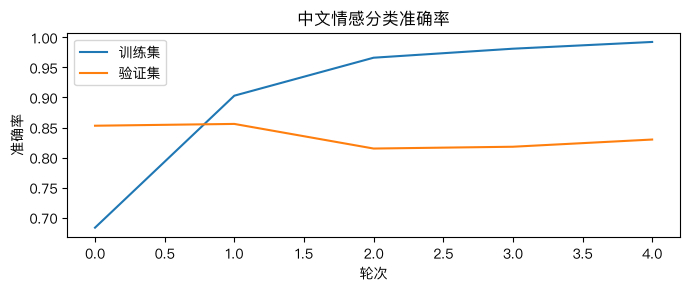

In [7]:
load_weights(checkpoint)
test_loss, test_accuracy = run_epoch(test_loader)
print(f"测试集准确率：{test_accuracy:.3f}；测试集损失：{test_loss:.4f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "max_length": MAX_LENGTH, "labels": LABELS,
           "split_sizes": [len(train_rows), len(validation_rows), len(test_rows)]}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
import matplotlib.pyplot as plt
from course_zh import setup_chinese_fonts
setup_chinese_fonts(plt)
print("图表中文字体：", setup_chinese_fonts(plt))
values = np.asarray(history)
fig, axis = plt.subplots(figsize=(7, 3))
axis.plot(values[:, 2], label="训练集")
axis.plot(values[:, 3], label="验证集")
axis.set(title="中文情感分类准确率", xlabel="轮次", ylabel="准确率")
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "accuracy.png")
plt.show()

**预期输出：**

```text
测试集准确率：0.876；测试集损失：0.3207
图表中文字体： PingFang SC
```

**预期输出（图片）：**

![重新加载并在留出测试集上评估](../assets/03-lstm-sentiment-1.png)

*重新加载并在留出测试集上评估*

## 5. 预测新的中文评论


In [8]:
reviews = ["这部电影非常精彩，表演也可圈可点。",
           "剧情很无聊，结局让人失望。",
           "本以为会讨厌它，结果竟然还不错。"]
probabilities = predict(reviews)
for text, scores in zip(reviews, probabilities):
    label = int(np.argmax(scores))
    print(f"{LABELS[label]} ({scores[label]:.3f}): {text}")

assert probabilities.shape == (len(reviews), 2)
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
# The same review should not change prediction because of other batch members.
assert np.allclose(predict([reviews[0]])[0], probabilities[0], atol=1e-5)
print("预测是会出错的，尤其是在课堂这种短时训练之后。")

正面 (0.545): 这部电影非常精彩，表演也可圈可点。
负面 (0.621): 剧情很无聊，结局让人失望。
正面 (0.531): 本以为会讨厌它，结果竟然还不错。
预测是会出错的，尤其是在课堂这种短时训练之后。


**预期输出：**

```text
正面 (0.545): 这部电影非常精彩，表演也可圈可点。
负面 (0.621): 剧情很无聊，结局让人失望。
正面 (0.531): 本以为会讨厌它，结果竟然还不错。
预测是会出错的，尤其是在课堂这种短时训练之后。
```

## 练习

对比单向与双向模型；改变最大长度并统计被截断的比例；观察含否定词和褒贬混合的评论。
所有调参都只能在验证集上进行。若以后要复现预测结果，必须同时恢复词表、最大长度、
网络结构、类别映射和权重。

想直接用已经微调好的中文预训练情感模型，请看 PyTorch 路线里的可选课程。
它的训练任务与本实验使用的酒店评论不同，官方公布的分数不能当成本课程的成绩。
